# NR-SL Channel Occupancy Analysis

Analyses **how the 5.8 GHz NR-SL sidelink bandwidth is actually used** across every simulation experiment:
what fraction of slots carry data, what fraction are reserved for HARQ feedback (PSFCH),
and what fraction are idle — and **why**.

**Experiments covered**
| Dir | Description |
|-----|-------------|
| `traffic_class_eval` | Fixed MCS=14, no compression |
| `traffic_class_adaptive_eval` | Adaptive MCS (nackRate / raAPC) |
| `traffic_class_compress_eval` | Adaptive app-layer compression |

**Run order:** no pre-processing needed — reads `.db` files directly.

---
## Resource pool model

```
Numerology μ=1  →  slot duration = 0.5 ms  (2 slots / subframe)
Active window   = simTime × 2000 slots/s   (= 120 000 slots for 60 s runs)

┌──────────────────────────── 120 000 slots ────────────────────────────┐
│  PSFCH  (30 000 = 25 %)  │         PSSCH-eligible (90 000 = 75 %)    │
│  every 4th slot reserved │  ┌─ data used ─┐  ┌── idle / empty ───┐  │
│  for HARQ ACK/NACK       │  │  (varies)   │  │   (varies)        │  │
└──────────────────────────┘  └─────────────┘  └───────────────────┘  │
└───────────────────────────────────────────────────────────────────────┘

Each PSSCH-eligible slot × n_subchannels  →  subchannel-slot resource units
Each grant uses ceil(rbLen / sbChSize) subchannels in one slot.
```
**PSFCH:** one in every `psfchPeriod` (=4) pool slots is reserved for HARQ feedback.  
Those slots cannot carry data and do not appear in `psschTxUeMac`.  
Each PSFCH slot can carry one ACK/NACK per PRB.

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})

# ── locate the shared channel_occupancy module ────────────────────────────
REPO = Path('..').resolve()   # scratch_overlay parent = repo root
OVERLAY = REPO / 'scratch_overlay'
if str(OVERLAY) not in sys.path:
    sys.path.insert(0, str(OVERLAY))

from channel_occupancy import analyze_channel_occupancy, analyze_experiment, print_occupancy

# ── experiment result roots ───────────────────────────────────────────────
EXPERIMENTS = {
    'fixed_mcs14'     : OVERLAY / 'traffic_class_eval'          / 'results_traffic_class_eval',
    'adaptive_mcs'    : OVERLAY / 'traffic_class_adaptive_eval'  / 'results_traffic_class_adaptive_eval',
    'compress_adapt'  : OVERLAY / 'traffic_class_compress_eval'  / 'results_traffic_class_compress_eval',
}

CLASS_ORDER  = ['periodic1', 'periodic2', 'periodic3', 'aperiodic1', 'aperiodic2']
CLASS_LABELS = {
    'periodic1' : 'P1\n200B·10Hz',  'periodic2'  : 'P2\n1kB·10Hz',
    'periodic3' : 'P3\n45kB·1Hz',   'aperiodic1' : 'A1\n1kB·aperiodic',
    'aperiodic2': 'A2\n20kB·aperiodic',
}
EXP_COLORS = {'fixed_mcs14': '#1f77b4', 'adaptive_mcs': '#ff7f0e', 'compress_adapt': '#d62728'}

print('Experiments found:')
for k, p in EXPERIMENTS.items():
    n = len(list(p.rglob('*_seed*.db'))) if p.exists() else 0
    print(f'  {k:<20} {n:>4} DBs   {p}')

Experiments found:
  fixed_mcs14           100 DBs   /Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/traffic_class_eval/results_traffic_class_eval
  adaptive_mcs          100 DBs   /Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/traffic_class_adaptive_eval/results_traffic_class_adaptive_eval
  compress_adapt        100 DBs   /Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/traffic_class_compress_eval/results_traffic_class_compress_eval


## 2. Single-DB deep dive
Run the full analysis on one representative DB and print all layers.


────────────────────────────────────────────────────────────
  DB : aperiodic2_seed1.db
  Slot duration : 0.5 ms  (μ=1)
  Subchannels   : 10  |  bwPRBs : 10
────────────────────────────────────────────────────────────

  ── Layer 1: Slot-level (of 120,000 total slots) ──
    PSFCH reserved  :   30,000  ( 25.0 %)
    Data TX         :    7,740  (  6.5 %)
      of which retx :        0  (retx ratio 0.0 %)
    Empty (idle)    :   82,260  ( 68.5 %)

  ── Layer 2: Subchannel×slot (of 900,000 PSSCH-eligible) ──
    Data used       :     57,724  (  6.4 %)
    Empty           :    842,276  ( 93.6 %)

  ── Layer 3: HARQ feedback (capacity 300,000 PRB-slots) ──
    ACK             :   52,084
    NACK            :    8,606
    Total FB sent   :   60,690  (20.23 % of PSFCH cap)
    NACK rate       :     14.2 %



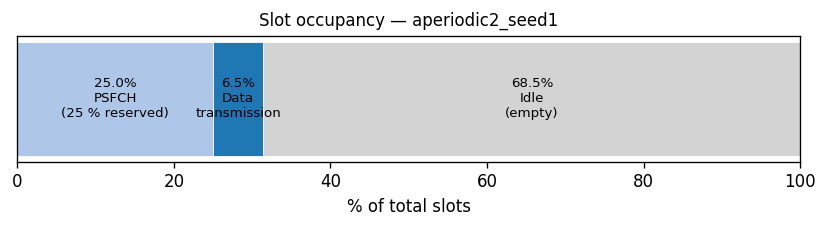

In [2]:
# ── Change these two lines to inspect any DB ─────────────────────────────
DEMO_DB = EXPERIMENTS['compress_adapt'] / 'adaptive' / 'aperiodic2' / 'aperiodic2_seed1.db'
DEMO_CSV = DEMO_DB.with_name(DEMO_DB.stem + '_run.csv')
# ─────────────────────────────────────────────────────────────────────────

r = analyze_channel_occupancy(DEMO_DB, run_csv=DEMO_CSV)
print_occupancy(r)

# Stacked-bar visualisation for this single run
fig, ax = plt.subplots(figsize=(7, 2))
T = r['total_slots']
fracs = [
    ('PSFCH\n(25 % reserved)',    r['frac_psfch'],       '#aec7e8'),
    ('Data\ntransmission',         r['frac_data_slots'],  '#1f77b4'),
    ('Idle\n(empty)',              r['frac_empty_slots'], '#d3d3d3'),
]
left = 0
for label, frac, color in fracs:
    ax.barh(0, frac*100, left=left*100, color=color, edgecolor='white', linewidth=0.5)
    if frac > 0.03:
        ax.text(left*100 + frac*50, 0, f'{frac*100:.1f}%\n{label}',
                ha='center', va='center', fontsize=8, color='black')
    left += frac
ax.set_xlim(0, 100)
ax.set_yticks([])
ax.set_xlabel('% of total slots')
ax.set_title(f'Slot occupancy — {DEMO_DB.stem}', fontsize=10)
plt.tight_layout()
plt.show()

### 2b. Subchannel-slot view (frequency × time)

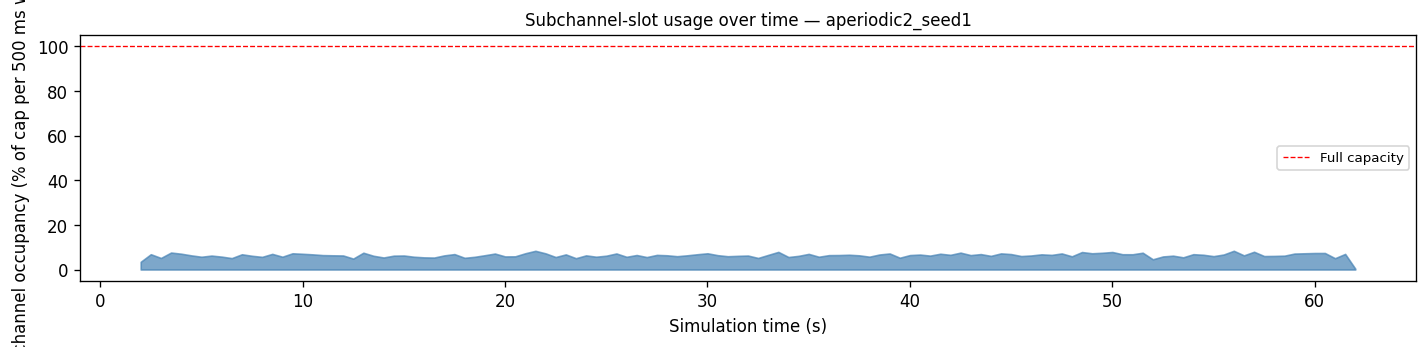

Mean occupancy: 6.4 %  (peak: 8 %)


In [3]:
import sqlite3

conn = sqlite3.connect(str(DEMO_DB))
grants = pd.read_sql_query(
    'SELECT frame, subFrame, slot, rbLen, sbChSize FROM psschTxUeMac', conn)
conn.close()

grants['n_subch']  = (grants['rbLen'] / grants['sbChSize']).astype(int)
grants['slot_abs'] = grants['frame']*20 + grants['subFrame']*2 + grants['slot']

# Time-series of subchannel usage per 1000-slot bin (= 500 ms)
BIN = 1000
grants['bin'] = (grants['slot_abs'] // BIN) * BIN * 0.5  # bin start in ms
usage = grants.groupby('bin')['n_subch'].sum()
capacity_per_bin = BIN * (1 - 1/r['psfch_period'] if hasattr(r, 'psfch_period') else 0.75) * r['n_subchannels']
# psfch_period not stored in r dict directly; use frac_psfch
capacity_per_bin = BIN * (1 - r['frac_psfch']) * r['n_subchannels']

fig, ax = plt.subplots(figsize=(12, 3))
ax.fill_between(usage.index / 1000, usage.values / capacity_per_bin * 100,
                alpha=0.7, color='steelblue')
ax.axhline(100, ls='--', color='red', lw=0.8, label='Full capacity')
ax.set_xlabel('Simulation time (s)')
ax.set_ylabel('Subchannel occupancy (% of cap per 500 ms window)')
ax.set_title(f'Subchannel-slot usage over time — {DEMO_DB.stem}', fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f'Mean occupancy: {usage.mean() / capacity_per_bin * 100:.1f} %  '
      f'(peak: {usage.max() / capacity_per_bin * 100:.0f} %)')

## 3. Load all experiments
Loop over every DB in every experiment directory.

In [4]:
dfs = []
for exp_name, results_dir in EXPERIMENTS.items():
    if not results_dir.exists():
        print(f'  [skip] {exp_name} — results not found')
        continue
    print(f'Loading {exp_name} ...')
    df = analyze_experiment(results_dir)
    df['experiment'] = exp_name
    dfs.append(df)
    print(f'  {len(df)} runs loaded')

occ = pd.concat(dfs, ignore_index=True)
print(f'\nTotal rows: {len(occ)}')
print(occ[['experiment','trafficClass','seed',
           'frac_psfch','frac_data_slots','frac_empty_slots',
           'frac_data_subch','frac_psfch_used','retx_ratio']].head(6))

Loading fixed_mcs14 ...


  100 runs loaded
Loading adaptive_mcs ...


  100 runs loaded
Loading compress_adapt ...


  100 runs loaded

Total rows: 300
    experiment trafficClass  seed  frac_psfch  frac_data_slots  \
0  fixed_mcs14   aperiodic1     1        0.25         0.004883   
1  fixed_mcs14   aperiodic1    10        0.25         0.005033   
2  fixed_mcs14   aperiodic1    11        0.25         0.005017   
3  fixed_mcs14   aperiodic1    12        0.25         0.004908   
4  fixed_mcs14   aperiodic1    13        0.25         0.004850   
5  fixed_mcs14   aperiodic1    14        0.25         0.004967   

   frac_empty_slots  frac_data_subch  frac_psfch_used  retx_ratio  
0          0.745117         0.003444         0.033427         0.0  
1          0.744967         0.003622         0.031843         0.0  
2          0.744983         0.003472         0.031650         0.0  
3          0.745092         0.003538         0.030947         0.0  
4          0.745150         0.003502         0.030380         0.0  
5          0.745033         0.003573         0.030997         0.0  


## 4. Slot-level occupancy per traffic class
### 4a. PSFCH | Data | Idle breakdown (stacked bars)

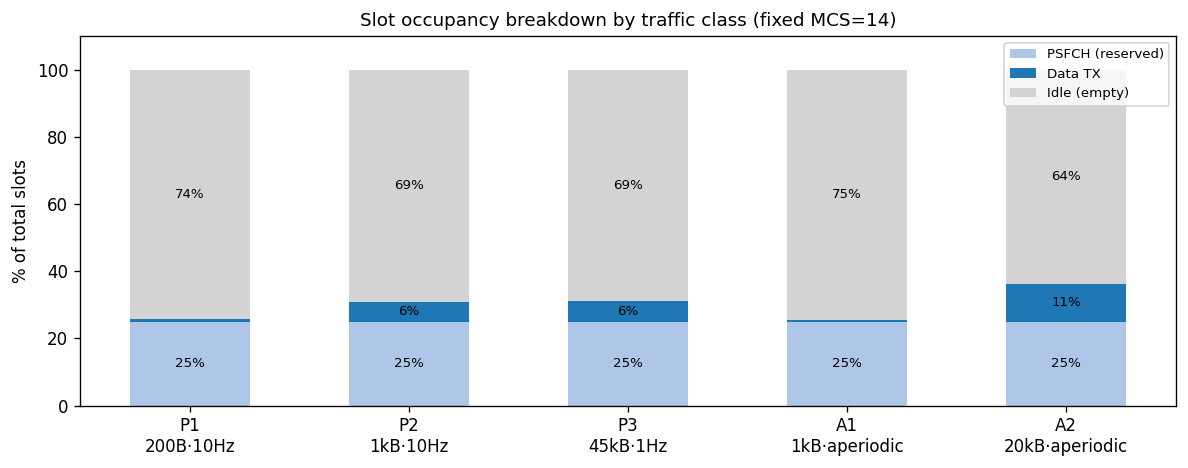

In [5]:
# Use fixed_mcs14 as the reference for a clean comparison (same traffic, no scheme effects)
ref = occ[occ.experiment == 'fixed_mcs14'].copy()
if ref.empty:
    ref = occ.copy()   # fallback: use whatever is available

classes = [c for c in CLASS_ORDER if c in ref.trafficClass.unique()]
mean_occ = ref.groupby('trafficClass')[[
    'frac_psfch', 'frac_data_slots', 'frac_empty_slots']].mean()

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(classes))
w = 0.55
bottom = np.zeros(len(classes))
for col, label, color in [
    ('frac_psfch',       'PSFCH (reserved)',   '#aec7e8'),
    ('frac_data_slots',  'Data TX',            '#1f77b4'),
    ('frac_empty_slots', 'Idle (empty)',        '#d3d3d3'),
]:
    vals = mean_occ.reindex(classes)[col].values * 100
    bars = ax.bar(x, vals, w, bottom=bottom, label=label, color=color)
    for xi, (b, v) in enumerate(zip(bottom, vals)):
        if v > 2:
            ax.text(xi, b + v/2, f'{v:.0f}%', ha='center', va='center',
                    fontsize=8, color='black')
    bottom += vals
ax.set_xticks(x)
ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in classes])
ax.set_ylabel('% of total slots')
ax.set_ylim(0, 110)
ax.legend(loc='upper right', fontsize=8)
ax.set_title('Slot occupancy breakdown by traffic class (fixed MCS=14)', fontsize=11)
plt.tight_layout()
plt.show()

### 4b. Data-slot occupancy violin — seed-to-seed variability

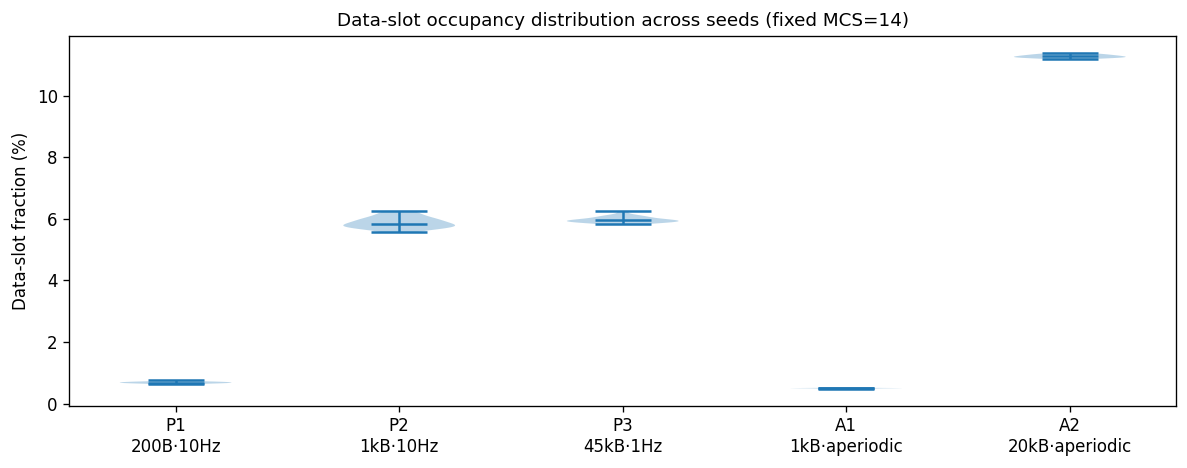

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
data = [ref[ref.trafficClass == c]['frac_data_slots'].values * 100 for c in classes]
parts = ax.violinplot(data, positions=range(len(classes)), showmedians=True)
ax.set_xticks(range(len(classes)))
ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in classes])
ax.set_ylabel('Data-slot fraction (%)')
ax.set_title('Data-slot occupancy distribution across seeds (fixed MCS=14)', fontsize=11)
plt.tight_layout()
plt.show()

## 5. Subchannel-slot occupancy (time × frequency)
More granular than slot-level: accounts for how many subchannels each grant occupies.

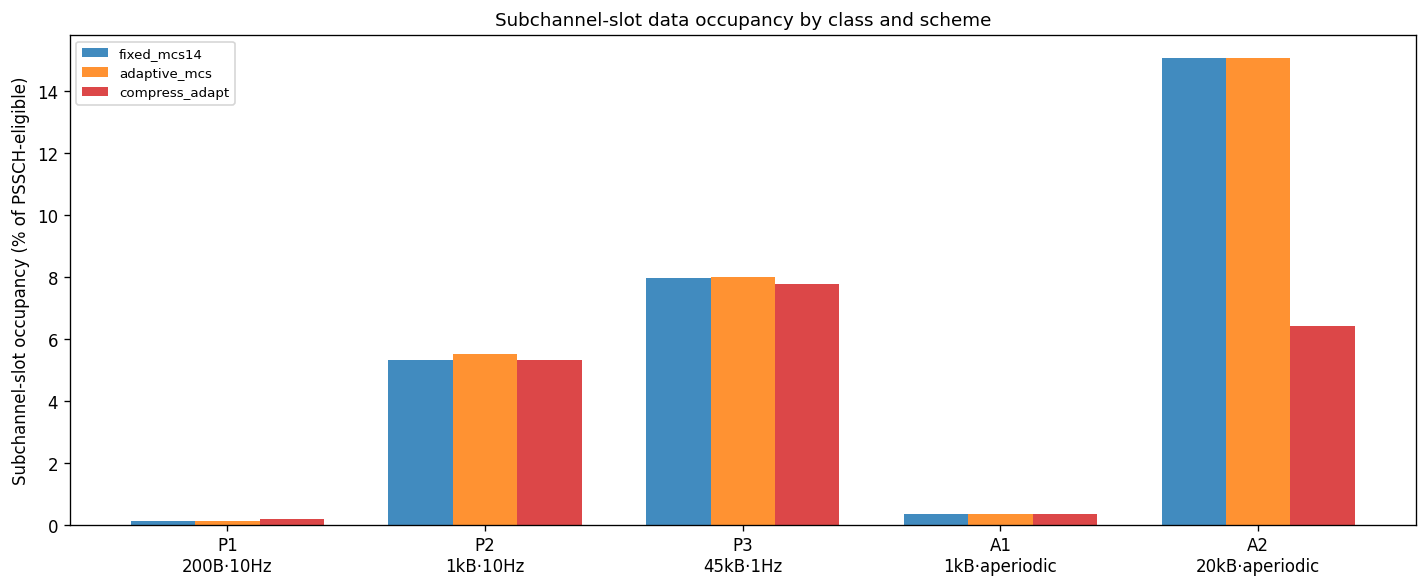

trafficClass,periodic1,periodic2,periodic3,aperiodic1,aperiodic2
experiment,,,,,
adaptive_mcs,0.12,5.50,7.97,0.33,15.05
compress_adapt,0.17,5.32,7.76,0.35,6.42
fixed_mcs14,0.11,5.30,7.96,0.35,15.05


In [7]:
classes = [c for c in CLASS_ORDER if c in occ.trafficClass.unique()]
experiments = [e for e in ['fixed_mcs14','adaptive_mcs','compress_adapt']
               if e in occ.experiment.unique()]

x = np.arange(len(classes))
width = 0.25
fig, ax = plt.subplots(figsize=(12, 5))

for ei, exp in enumerate(experiments):
    sub = occ[occ.experiment == exp]
    vals = [sub[sub.trafficClass == c]['frac_data_subch'].mean() * 100 for c in classes]
    offset = (ei - len(experiments)/2 + 0.5) * width
    ax.bar(x + offset, vals, width, label=exp, color=EXP_COLORS.get(exp, f'C{ei}'), alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in classes])
ax.set_ylabel('Subchannel-slot occupancy (% of PSSCH-eligible)')
ax.set_title('Subchannel-slot data occupancy by class and scheme', fontsize=11)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Table
pivot = occ.groupby(['experiment','trafficClass'])['frac_data_subch'].mean().unstack()
display((pivot * 100).round(2).reindex(columns=[c for c in CLASS_ORDER if c in pivot.columns]))

## 6. HARQ feedback utilisation (Layer 3)

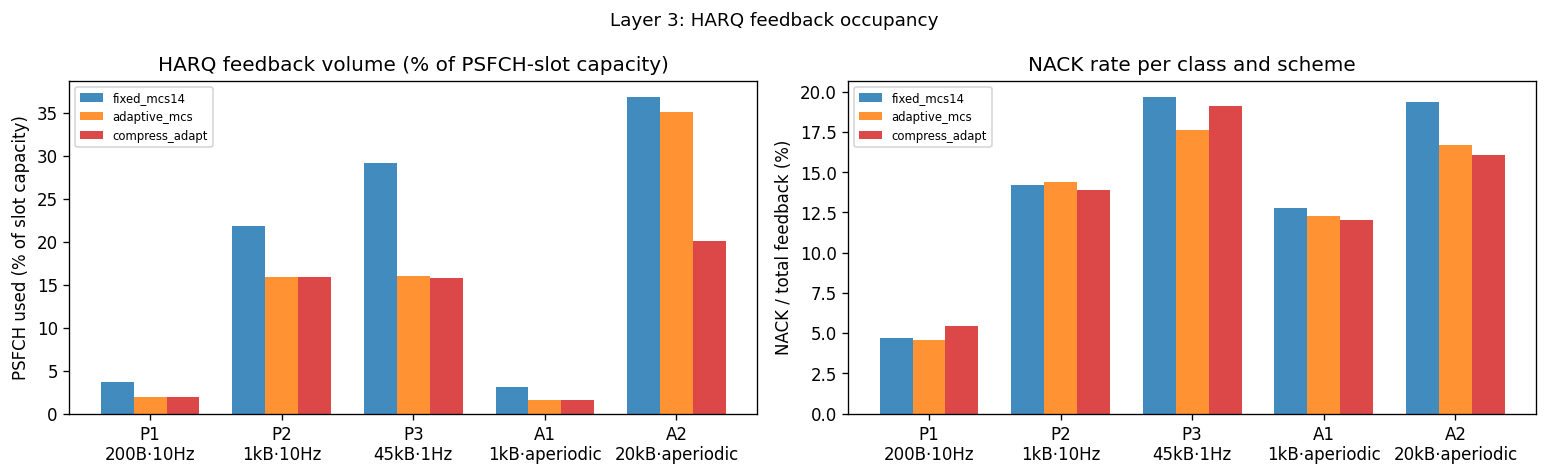

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# ─ PSFCH used fraction ───────────────────────────────────────────────────
ax = axes[0]
for ei, exp in enumerate(experiments):
    sub = occ[occ.experiment == exp]
    vals = [sub[sub.trafficClass==c]['frac_psfch_used'].mean()*100 for c in classes]
    offset = (ei - len(experiments)/2 + 0.5) * width
    ax.bar(x + offset, vals, width, label=exp, color=EXP_COLORS.get(exp,f'C{ei}'), alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in classes])
ax.set_ylabel('PSFCH used (% of slot capacity)')
ax.set_title('HARQ feedback volume (% of PSFCH-slot capacity)')
ax.legend(fontsize=7)

# ─ NACK rate ─────────────────────────────────────────────────────────────
ax = axes[1]
for ei, exp in enumerate(experiments):
    sub = occ[occ.experiment == exp]
    vals = [sub[sub.trafficClass==c]['frac_nack'].mean()*100 for c in classes]
    offset = (ei - len(experiments)/2 + 0.5) * width
    ax.bar(x + offset, vals, width, label=exp, color=EXP_COLORS.get(exp,f'C{ei}'), alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in classes])
ax.set_ylabel('NACK / total feedback (%)')
ax.set_title('NACK rate per class and scheme')
ax.legend(fontsize=7)

fig.suptitle('Layer 3: HARQ feedback occupancy', fontsize=11)
plt.tight_layout()
plt.show()

## 7. Retransmission ratio

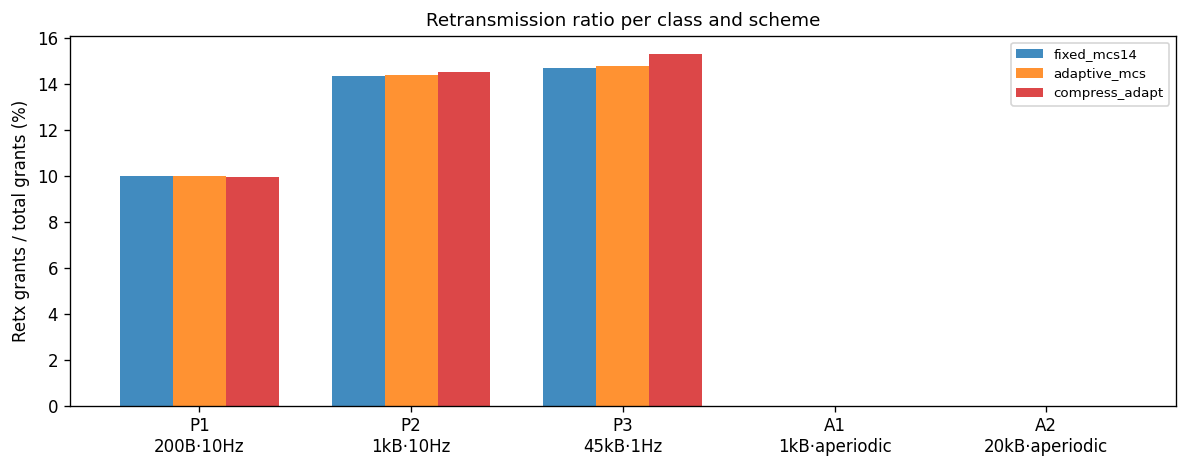

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for ei, exp in enumerate(experiments):
    sub = occ[occ.experiment == exp]
    vals = [sub[sub.trafficClass==c]['retx_ratio'].mean()*100 for c in classes]
    offset = (ei - len(experiments)/2 + 0.5) * width
    ax.bar(x + offset, vals, width, label=exp, color=EXP_COLORS.get(exp,f'C{ei}'), alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in classes])
ax.set_ylabel('Retx grants / total grants (%)')
ax.set_title('Retransmission ratio per class and scheme', fontsize=11)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Summary table — all three layers, all experiments

In [10]:
agg_cols = [
    'frac_psfch', 'frac_data_slots', 'frac_empty_slots',
    'frac_data_subch', 'frac_empty_subch',
    'frac_psfch_used', 'frac_nack', 'retx_ratio',
]
summary = (occ.groupby(['experiment','trafficClass'])[agg_cols]
             .mean()
             .multiply(100)
             .round(1)
             .reset_index())
summary.columns = [
    'Experiment', 'Class',
    'PSFCH%','Data slots%','Idle slots%',
    'Data subch%','Idle subch%',
    'PSFCH used%','NACK rate%','Retx%',
]
summary = summary[summary['Class'].isin(CLASS_ORDER)]
summary['Class'] = pd.Categorical(summary['Class'], CLASS_ORDER, ordered=True)
summary = summary.sort_values(['Experiment','Class'])
pd.set_option('display.max_columns', 20, 'display.width', 120)
display(summary)

,Experiment,Class,PSFCH%,Data slots%,Idle slots%,Data subch%,Idle subch%,PSFCH used%,NACK rate%,Retx%
2,adaptive_mcs,periodic1,25.0,0.7,74.3,0.1,99.9,2.0,4.6,10.0
3,adaptive_mcs,periodic2,25.0,5.9,69.1,5.5,94.5,15.9,14.4,14.4
4,adaptive_mcs,periodic3,25.0,6.0,69.0,8.0,92.0,16.0,17.6,14.8
0,adaptive_mcs,aperiodic1,25.0,0.5,74.5,0.3,99.7,1.6,12.3,0.0
1,adaptive_mcs,aperiodic2,25.0,11.3,63.7,15.0,85.0,35.1,16.7,0.0
7,compress_adapt,periodic1,25.0,0.7,74.3,0.2,99.8,1.9,5.5,10.0
8,compress_adapt,periodic2,25.0,5.9,69.1,5.3,94.7,15.9,13.9,14.5
9,compress_adapt,periodic3,25.0,5.9,69.1,7.8,92.2,15.8,19.1,15.3
5,compress_adapt,aperiodic1,25.0,0.5,74.5,0.4,99.6,1.6,12.1,0.0
6,compress_adapt,aperiodic2,25.0,6.4,68.6,6.4,93.6,20.1,16.1,0.0


## 9. Interpretation — why the numbers are as they are

### 9a. PSFCH is always exactly 25 %

`psfchPeriod = 4` is fixed across all experiments. The SL pool reserves every 4th slot
for HARQ feedback regardless of traffic load. This 25 % overhead is a **hard structural cost**
of enabling HARQ in NR-SL Mode 2.

In [11]:
print('PSFCH fraction statistics (should be exactly 0.25 for all runs):')
print(occ['frac_psfch'].describe())

PSFCH fraction statistics (should be exactly 0.25 for all runs):
count    300.00
mean       0.25
std        0.00
min        0.25
25%        0.25
50%        0.25
75%        0.25
max        0.25
Name: frac_psfch, dtype: float64


### 9b. Data-slot occupancy is LOW for all classes (<10 %)

Even for high-rate classes the fraction of PSSCH-eligible slots that contain a grant is small.
This is **by design** in NR-SL Mode 2 (SB-SPS):

* The TX selects resources from a sensing-based candidate list.
  Only one grant per RRI (Resource Reservation Interval, typically 20–100 ms).
* 1 Hz periodic3: 1 TX per second = 1 slot used per 2000 PSSCH-eligible slots = **0.05 %**.
* 10 Hz periodic1/2: 10 TXs per second × (1 + maxNumTx=2 grants) = ~30 slots / 90 000 ≈ **0.033 %**.
* aperiodic classes: bursty, duty cycle << 1.

The apparent paradox — high occupancy in the **subchannel** dimension for large classes (aperiodic2
uses 10/10 subchannels per grant) while still being sparse in time — is explained by the fact
that NR-SL schedules **frequency-wide but time-sparse** grants.

In [12]:
if 'fixed_mcs14' in occ.experiment.unique():
    ref = occ[occ.experiment == 'fixed_mcs14']
    comp = ref.groupby('trafficClass')[['frac_data_slots','frac_data_subch']].mean() * 100
    print(comp.reindex([c for c in CLASS_ORDER if c in comp.index]).round(3))
    print()
    print('Ratio subch_occ / slot_occ  (how many subchannels per used slot on average):')
    ratio = comp['frac_data_subch'] / comp['frac_data_slots'].clip(lower=1e-6)
    print(ratio.round(1))

              frac_data_slots  frac_data_subch
trafficClass                                  
periodic1               0.683            0.114
periodic2               5.884            5.304
periodic3               5.973            7.964
aperiodic1              0.497            0.352
aperiodic2             11.287           15.050

Ratio subch_occ / slot_occ  (how many subchannels per used slot on average):
trafficClass
aperiodic1    0.7
aperiodic2    1.3
periodic1     0.2
periodic2     0.9
periodic3     1.3
dtype: float64


### 9c. Large-payload classes dominate PSSCH bandwidth

When a grant *does* fire for aperiodic2 / periodic3, it uses **all 10 subchannels** (100 PRBs)
because the SDU is fragmented across multiple RLC segments, each requiring the full BW to fit
a TB large enough to carry the segment. This is why subchannel occupancy can be 6–8× higher
than slot occupancy for these classes.

With compression (`compress_adapt`), the same aperiodic2 SDU is compressed to ~21 % of its
original size. Fewer subchannels are needed per grant for the small classes, but aperiodic2
still uses all 10 (the compressed payload still needs 2 TBs, each full BW). Hence subchannel
occupancy hardly changes but PRR doubles.

In [13]:
# Show how subch occupancy changes with compression
if all(e in occ.experiment.unique() for e in ['fixed_mcs14','compress_adapt']):
    comp_diff = (
        occ.groupby(['experiment','trafficClass'])['frac_data_subch'].mean()
           .unstack('experiment') * 100
    )
    comp_diff['Δ compress-fixed'] = comp_diff.get('compress_adapt',0) - comp_diff.get('fixed_mcs14',0)
    print('Subchannel occupancy (%) and change with compression:')
    print(comp_diff.reindex([c for c in CLASS_ORDER if c in comp_diff.index]).round(2))

Subchannel occupancy (%) and change with compression:
experiment    adaptive_mcs  compress_adapt  fixed_mcs14  Δ compress-fixed
trafficClass                                                             
periodic1             0.12            0.17         0.11              0.06
periodic2             5.50            5.32         5.30              0.01
periodic3             7.97            7.76         7.96             -0.20
aperiodic1            0.33            0.35         0.35              0.00
aperiodic2           15.05            6.42        15.05             -8.63


### 9d. PSFCH utilisation is proportional to traffic load × n_receivers

Each received TB triggers one ACK or NACK from each receiver.
With 8 receivers and 7 740 grants for aperiodic2 (seed 1):
> 7 740 × 8 = ~61 920 expected feedback events  
> Actual: 60 690 (some lost due to SCI decode failures).

PSFCH slot capacity = 30 000 slots × bwPRBs = 300 000 subchannel-slots.  
Utilisation = 60 690 / 300 000 ≈ **20 %** — plenty of feedback headroom.  
For periodic1 (200 B, 10 Hz) with far fewer grants, PSFCH utilisation will be much lower.

In [14]:
if 'fixed_mcs14' in occ.experiment.unique():
    ref = occ[occ.experiment == 'fixed_mcs14']
    fb = ref.groupby('trafficClass')[['frac_psfch_used','harq_fb_total','data_slots']].mean()
    fb['fb_per_grant'] = fb['harq_fb_total'] / fb['data_slots'].clip(lower=1)
    print('HARQ feedback statistics (fixed_mcs14):')
    print(fb.reindex([c for c in CLASS_ORDER if c in fb.index]).round(2))

HARQ feedback statistics (fixed_mcs14):
              frac_psfch_used  harq_fb_total  data_slots  fb_per_grant
trafficClass                                                          
periodic1                0.04       11025.65      819.30         13.46
periodic2                0.22       65539.15     7060.80          9.28
periodic3                0.29       87407.25     7168.05         12.19
aperiodic1               0.03        9425.35      596.50         15.80
aperiodic2               0.37      110572.90    13544.75          8.16


### 9e. Idle slots: structural vs opportunity

Two types of idleness exist in the pool:

1. **Structural idle** — slots where the sensing-based scheduler found no viable candidate
   (e.g., collision avoidance excluded all options).
2. **Opportunity idle** — offered load is simply too low to fill the pool
   (e.g., periodic1 at 10 Hz with 200 B packets only needs 1 slot per 200 ms).

The dominant cause here is (2): **the protocol is severely under-loaded for all five classes**.
Even periodic3 with 45 kB packets at 1 Hz uses only ~6 % of PSSCH slots (each 45 kB SDU
fragments into 19 RLC segments → 19 grants × 1 slot each; still << 90 000 eligible slots).

This is realistic for V2X groupcast where:
- 1 TX node, 8 RX nodes
- Each TX sends at its own application rate
- The pool is sized for a dense vehicular scenario with many concurrent TXs

In a scenario with N=50 vehicles all transmitting simultaneously,
the idle fraction would shrink and collision probability would rise.

In [15]:
# Compute offered load (grants per second) vs pool capacity (slots per second)
SIM_S = 60.0
SLOT_MS = 0.5
PSSCH_SLOTS_PER_SEC = (1000.0 / SLOT_MS) * 0.75  # 75% of slots are PSSCH-eligible

if 'fixed_mcs14' in occ.experiment.unique():
    ref = occ[occ.experiment == 'fixed_mcs14']
    load = ref.groupby('trafficClass')['data_slots'].mean() / SIM_S
    print(f'PSSCH pool capacity: {PSSCH_SLOTS_PER_SEC:.0f} slots/s')
    print()
    print('Offered load (grants/s) and pool utilisation:')
    for cls in [c for c in CLASS_ORDER if c in load.index]:
        g_per_s = load[cls]
        util = g_per_s / PSSCH_SLOTS_PER_SEC * 100
        print(f'  {cls:<12}  {g_per_s:6.1f} grants/s   →  pool util {util:.3f} %')

PSSCH pool capacity: 1500 slots/s

Offered load (grants/s) and pool utilisation:
  periodic1       13.7 grants/s   →  pool util 0.910 %
  periodic2      117.7 grants/s   →  pool util 7.845 %
  periodic3      119.5 grants/s   →  pool util 7.965 %
  aperiodic1       9.9 grants/s   →  pool util 0.663 %
  aperiodic2     225.7 grants/s   →  pool util 15.050 %


## 10. Export
Save the full occupancy table for use in other notebooks.

In [16]:
out = OVERLAY / 'channel_occupancy_all.csv'
occ.to_csv(out, index=False)
print(f'Saved {len(occ)} rows → {out}')

Saved 300 rows → /Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/channel_occupancy_all.csv
